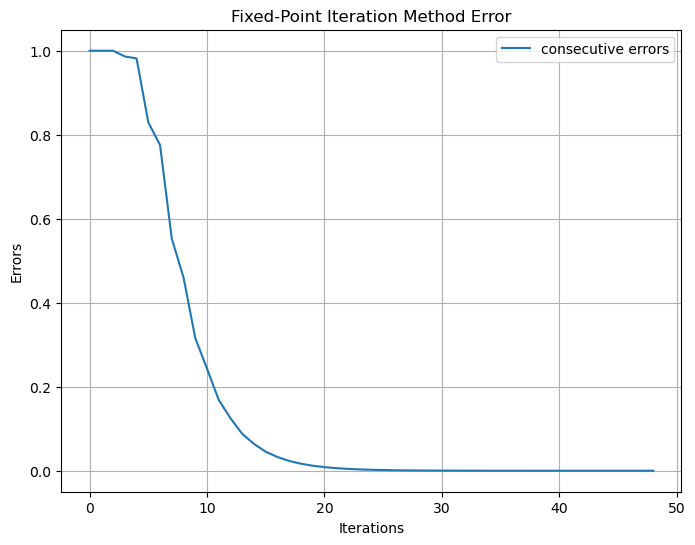

pk =  0.9999987122531745
Ck =  0.7159537668240632


In [2]:
import numpy as np
import matplotlib.pyplot as plt

#Prerequisites & function declerations
#Stopping tolerance and maximum iteration limits
tol = 1e-6
max_iter = 100

#We declare the function f(x) of the non-linear equation f(x) = x^3 + x - 1 = 0
def f(x):
    return x**3 + x - 1

# We declare the rearrangement g(x) = (1 - x)^(1/3)
def g(x):
    return np.cbrt(1.0 - x) #we use np.cbrt() to safely calculate real cube roots (even at 0 or negative values)
    
# 1.Fixed-Point Iteration Method function
def FPI(x0):
    x_k = [x0] #We initialize a list to store all successive approximations x_k
    err = [] #We initialize a list to store all consecutive errors e_k for each iteration step
    for i in range(max_iter):        #We run the iteration loop up to max_iter
        x_next = g(x0)        #We calculate the next iterate: x_k+1 = g(x_k)
        x_k.append(x_next)
        err.append(np.abs(x_next - x0)) 

        #Convergence stopping criterion: |x_k+1 - x_k| < tol
        if np.abs(x_next - x0) < tol:
            break
        x0 = x_next #We update current estimate for the next step
        
    return x_k, err

# 2. matplotlib plot
x_k, errors = FPI(1e-15)

iterations = range(len(errors))
#We generate the error convergence plot
plt.figure( figsize=(8,6) )
plt.plot(iterations, errors, label='consecutive errors')
plt.xlabel('Iterations')
plt.ylabel('Errors')
plt.title('Fixed-Point Iteration Method Error')
plt.grid()
plt.legend()
plt.show()

# 3. Asymptotic convergence estimation
#We extract the last three valid errors: e_{k-1}, e_k, and e_{k+1}
e_k2 = errors[- 1] #e_{k+1}
e_k1 = errors[- 2] #e_k
e_k  = errors[- 3] #e_{k-1}

p_k = (np.log(e_k2 / e_k1) / np.log(e_k1 / e_k)) #We calculate the asymptotic convergence rate (p_k):
C_k = e_k2 / ((e_k1)**p_k) #We calculate the asymptotic error constant (Ck)

#We print the experimental results
print('pk = ', p_k)
print('Ck = ', C_k)